# Algorithmic Implementation of an AI Approach
## Genetic Algorithm for the Travelling Salesman Problem (15 Indian Cities)

**Course:** Artificial Intelligence and Soft Computing (CSE3121)
**Component:** Algorithmic Implementation of AI approaches with Viva (10 marks)
**Student:** Shashwat Shikhar Dwivedi (Roll No. 2427030605)
**Submitted to:** Dr. Neha Chaudhary

### Problem
A salesperson must visit each of 15 Indian cities exactly once and return to the start, minimising total distance.
There are $(15-1)!/2 \approx 4.4\times10^{10}$ distinct tours, so brute force is impractical, which makes this a good fit for a metaheuristic.

### Why a Genetic Algorithm?
A GA is a population-based search inspired by natural selection. It keeps many candidate tours at once and improves them through
**selection → crossover → mutation → elitism** over many generations.

### Plan of this notebook
1. Problem data and distance matrix
2. GA design (encoding, fitness, operators)
3. Implementation
4. Run and visualise
5. Validate against the **exact optimum** (Held-Karp dynamic programming)
6. Experiments: baselines, mutation rate, population size
7. Worked example of Order Crossover (for the viva)
8. Complexity and limitations
9. Conclusion

## 1. Imports and Problem Data

In [1]:
import math, random, time, os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs('figures', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

# (latitude, longitude)
CITIES = {
    'Delhi': (28.61, 77.21),     'Mumbai': (19.08, 72.88),   'Kolkata': (22.57, 88.36),
    'Chennai': (13.08, 80.27),   'Bengaluru': (12.97, 77.59), 'Hyderabad': (17.39, 78.49),
    'Ahmedabad': (23.02, 72.57), 'Pune': (18.52, 73.86),     'Jaipur': (26.91, 75.79),
    'Lucknow': (26.85, 80.95),   'Bhopal': (23.26, 77.41),   'Patna': (25.59, 85.14),
    'Chandigarh': (30.73, 76.78),'Guwahati': (26.14, 91.74), 'Kochi': (9.93, 76.27),
}
names = list(CITIES)
N = len(names)

def haversine(a, b):
    # great-circle distance in km
    R = 6371.0
    la1, lo1, la2, lo2 = map(math.radians, (*a, *b))
    h = math.sin((la2-la1)/2)**2 + math.cos(la1)*math.cos(la2)*math.sin((lo2-lo1)/2)**2
    return 2*R*math.asin(math.sqrt(h))

D = [[haversine(CITIES[a], CITIES[b]) for b in names] for a in names]
print(f'{N} cities loaded. Delhi -> Mumbai = {D[0][1]:.0f} km')

15 cities loaded. Delhi -> Mumbai = 1147 km


## 2. GA Design

| Component | Choice | Reason |
|---|---|---|
| **Chromosome** | Permutation of city indices, e.g. `[3, 0, 7, ...]` | Each city appears exactly once, so every chromosome is a valid tour |
| **Fitness** | $f = 1/L$, where $L$ is total tour length | Shorter tour means higher fitness |
| **Selection** | Tournament (size $k=5$) | Simple, tunable selection pressure, no fitness scaling needed |
| **Crossover** | Order Crossover (OX1), prob. 0.9 | Preserves the permutation property and relative city order |
| **Mutation** | Inversion of a random segment, prob. 0.2 | Reverses a sub-route, which is a natural move for TSP (2-opt-like) |
| **Elitism** | Best 2 individuals copied unchanged | Best fitness never decreases |
| **Termination** | Fixed number of generations | Easy to compare runs |

## 3. Implementation

In [2]:
def tour_length(tour):
    return sum(D[tour[i]][tour[(i+1) % N]] for i in range(N))

def fitness(tour):
    return 1.0 / tour_length(tour)

def random_tour():
    t = list(range(N)); random.shuffle(t); return t

def tournament_select(pop, lengths, k):
    # pick k random individuals, return the shortest tour among them
    idx = random.sample(range(len(pop)), k)
    return pop[min(idx, key=lambda i: lengths[i])]

def order_crossover(p1, p2):
    # OX1: copy a slice from p1, fill the rest in the order they appear in p2
    a, b = sorted(random.sample(range(N), 2))
    child = [None]*N
    child[a:b+1] = p1[a:b+1]
    fill = [g for g in p2 if g not in child[a:b+1]]
    pos = 0
    for i in range(N):
        if child[i] is None:
            child[i] = fill[pos]; pos += 1
    return child

def inversion_mutation(t):
    a, b = sorted(random.sample(range(N), 2))
    t = t[:]
    t[a:b+1] = reversed(t[a:b+1])
    return t

def genetic_algorithm(pop_size=150, generations=300, crossover_rate=0.9,
                      mutation_rate=0.2, tournament_k=5, elite=2, seed=None):
    if seed is not None:
        random.seed(seed)
    pop = [random_tour() for _ in range(pop_size)]
    best_hist, avg_hist = [], []
    best_tour, best_len = None, float('inf')

    for gen in range(generations):
        lengths = [tour_length(t) for t in pop]

        gen_best = min(range(pop_size), key=lambda i: lengths[i])
        if lengths[gen_best] < best_len:
            best_len, best_tour = lengths[gen_best], pop[gen_best][:]
        best_hist.append(best_len)
        avg_hist.append(sum(lengths)/pop_size)

        # elitism: carry over the best individuals unchanged
        order = sorted(range(pop_size), key=lambda i: lengths[i])
        new_pop = [pop[i][:] for i in order[:elite]]

        while len(new_pop) < pop_size:
            p1 = tournament_select(pop, lengths, tournament_k)
            p2 = tournament_select(pop, lengths, tournament_k)
            child = order_crossover(p1, p2) if random.random() < crossover_rate else p1[:]
            if random.random() < mutation_rate:
                child = inversion_mutation(child)
            new_pop.append(child)
        pop = new_pop

    return best_tour, best_len, best_hist, avg_hist

# sanity checks on operators
random.seed(0)
p1, p2 = random_tour(), random_tour()
c = order_crossover(p1, p2); m = inversion_mutation(c)
assert sorted(c) == list(range(N)) and sorted(m) == list(range(N))
print('Operators preserve valid permutations: OK')

Operators preserve valid permutations: OK


## 4. Run the GA and Visualise

In [3]:
t0 = time.time()
best_tour, best_len, best_hist, avg_hist = genetic_algorithm(seed=42)
print(f'Runtime: {time.time()-t0:.2f}s')
print(f'Best tour length: {best_len:.1f} km')
print('Route:', ' -> '.join(names[i] for i in best_tour), '->', names[best_tour[0]])

Runtime: 0.54s
Best tour length: 7745.4 km
Route: Mumbai -> Ahmedabad -> Jaipur -> Delhi -> Chandigarh -> Lucknow -> Patna -> Guwahati -> Kolkata -> Bhopal -> Hyderabad -> Chennai -> Bengaluru -> Kochi -> Pune -> Mumbai


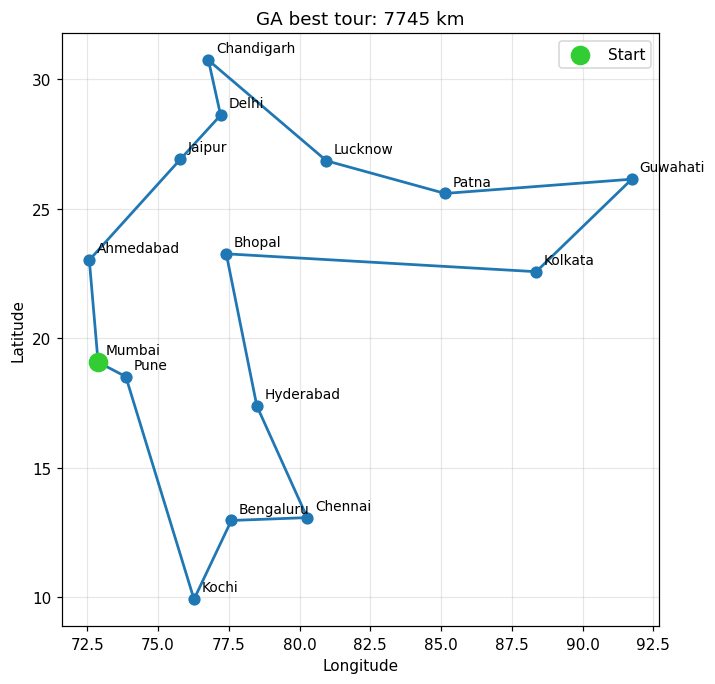

In [4]:
def plot_route(tour, title, fname=None):
    fig, ax = plt.subplots(figsize=(7, 7))
    pts = [CITIES[names[i]] for i in tour] + [CITIES[names[tour[0]]]]
    ax.plot([p[1] for p in pts], [p[0] for p in pts], '-o', color='tab:blue', lw=1.8, ms=7, zorder=2)
    for i in tour:
        lat, lon = CITIES[names[i]]
        ax.annotate(names[i], (lon, lat), textcoords='offset points', xytext=(5, 5), fontsize=9)
    s = CITIES[names[tour[0]]]
    ax.scatter(s[1], s[0], c='limegreen', s=140, zorder=3, label='Start')
    ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.set_title(title); ax.legend()
    if fname: fig.savefig(fname, bbox_inches='tight')
    plt.show()

plot_route(best_tour, f'GA best tour: {best_len:.0f} km', 'figures/ga_route.png')

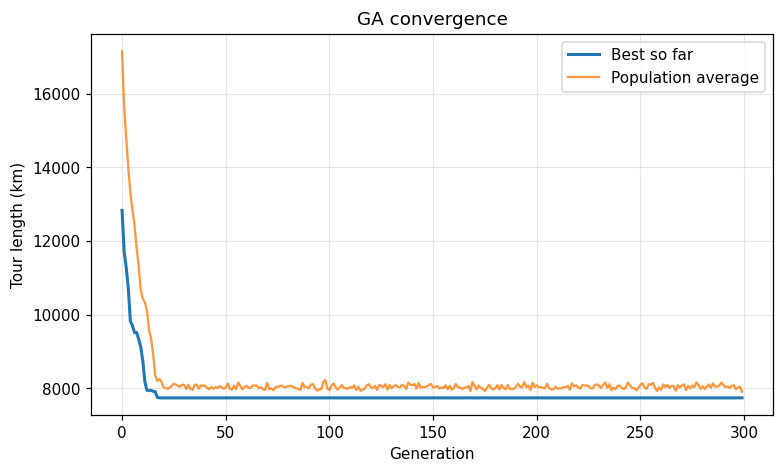

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(best_hist, label='Best so far', lw=2)
ax.plot(avg_hist, label='Population average', lw=1.5, alpha=0.8)
ax.set_xlabel('Generation'); ax.set_ylabel('Tour length (km)')
ax.set_title('GA convergence'); ax.legend()
fig.savefig('figures/ga_convergence.png', bbox_inches='tight')
plt.show()

## 5. Validation against the Exact Optimum (Held-Karp)

Held-Karp dynamic programming solves TSP exactly in $O(n^2 2^n)$. That is feasible for $n=15$, so we can measure how close the GA gets.

Exact optimum: 7478.9 km  (computed in 0.3s)
GA best:       7745.4 km
Gap to optimum: 3.56%
Note: one run can stall in a local optimum; Section 6.1 reports statistics over 10 runs.


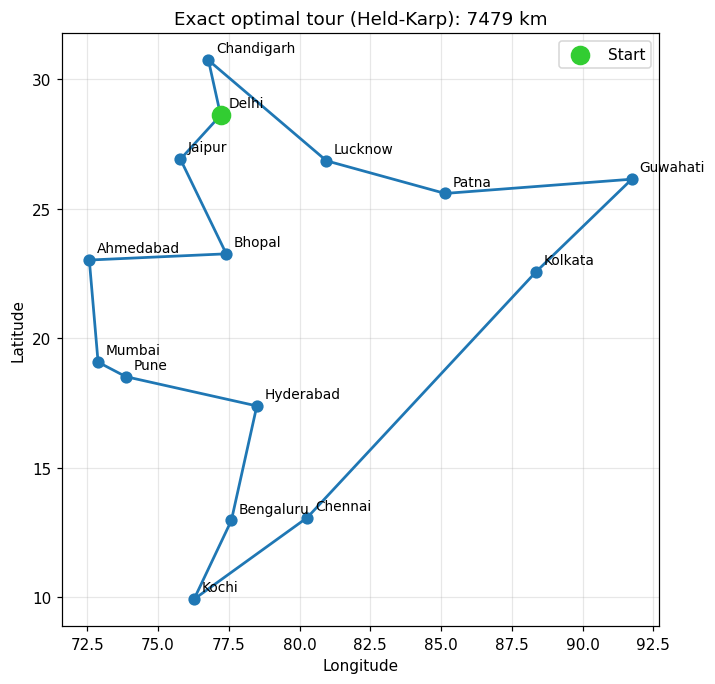

In [6]:
def held_karp(D):
    n = len(D)
    INF = float('inf')
    # dp[(mask, j)] = shortest path starting at 0, visiting set 'mask', ending at j
    dp = [[INF]*n for _ in range(1 << n)]
    parent = [[-1]*n for _ in range(1 << n)]
    dp[1][0] = 0
    for mask in range(1 << n):
        if not mask & 1: continue
        for j in range(n):
            if dp[mask][j] == INF: continue
            for k in range(n):
                if mask & (1 << k): continue
                nm = mask | (1 << k)
                v = dp[mask][j] + D[j][k]
                if v < dp[nm][k]:
                    dp[nm][k] = v; parent[nm][k] = j
    full = (1 << n) - 1
    best, last = min((dp[full][j] + D[j][0], j) for j in range(1, n))
    tour, mask = [], full
    while last != -1:
        tour.append(last); mask, last = mask ^ (1 << last), parent[mask][last]
    return best, tour[::-1]

t0 = time.time()
opt_len, opt_tour = held_karp(D)
print(f'Exact optimum: {opt_len:.1f} km  (computed in {time.time()-t0:.1f}s)')
print(f'GA best:       {best_len:.1f} km')
print(f'Gap to optimum: {100*(best_len-opt_len)/opt_len:.2f}%')
print('Note: one run can stall in a local optimum; Section 6.1 reports statistics over 10 runs.')
plot_route(opt_tour, f'Exact optimal tour (Held-Karp): {opt_len:.0f} km', 'figures/optimal_route.png')

## 6. Experiments

### 6.1 GA versus baselines (random search, nearest-neighbour)

In [7]:
def nearest_neighbour(start=0):
    unvisited = set(range(N)) - {start}; tour = [start]
    while unvisited:
        nxt = min(unvisited, key=lambda j: D[tour[-1]][j])
        tour.append(nxt); unvisited.remove(nxt)
    return tour

def random_search(evals, seed):
    random.seed(seed)
    return min(tour_length(random_tour()) for _ in range(evals))

nn_len = tour_length(nearest_neighbour())
evals = 150 * 300      # same budget as the GA: population x generations
rs_len = np.mean([random_search(evals, s) for s in range(3)])

SEEDS = range(10)
ga_lens = [genetic_algorithm(seed=s)[1] for s in SEEDS]

import pandas as pd
table = pd.DataFrame({
    'Method': ['Random search (same budget, mean of 3)', 'Nearest neighbour', 'Genetic Algorithm (mean of 10 runs)',
               'Genetic Algorithm (best of 10 runs)', 'Exact optimum (Held-Karp)'],
    'Length (km)': [rs_len, nn_len, np.mean(ga_lens), min(ga_lens), opt_len],
})
table['Gap to optimum (%)'] = 100*(table['Length (km)'] - opt_len)/opt_len
table['Gap to optimum (%)'] = table['Gap to optimum (%)'].clip(lower=0)
table = table.round(1)
table.to_csv('figures/baselines.csv', index=False)
print(table.to_string(index=False))
print('GA runs reaching the optimum:', sum(abs(l-opt_len) < 1e-6 for l in ga_lens), 'of', len(ga_lens))

                                Method  Length (km)  Gap to optimum (%)
Random search (same budget, mean of 3)       9930.4                32.8
                     Nearest neighbour       9169.4                22.6
   Genetic Algorithm (mean of 10 runs)       7526.9                 0.6
   Genetic Algorithm (best of 10 runs)       7478.9                 0.0
             Exact optimum (Held-Karp)       7478.9                 0.0
GA runs reaching the optimum: 5 of 10


### 6.2 Effect of mutation rate

 Mutation rate  Mean length (km)  Best length (km)
          0.00            8079.0            7503.7
          0.05            7660.8            7478.9
          0.20            7532.2            7478.9
          0.50            7545.6            7478.9
          0.90            7478.9            7478.9


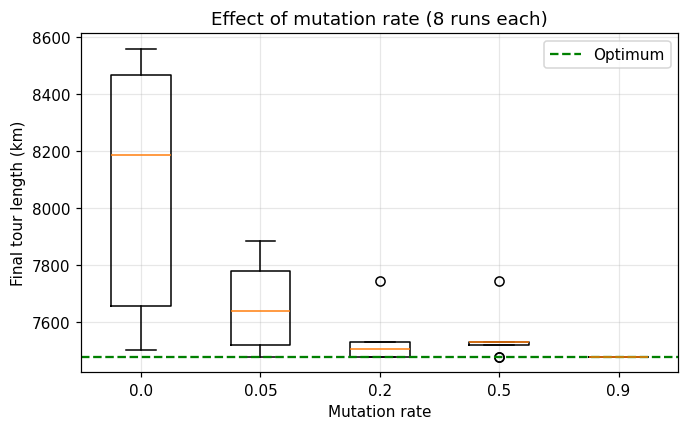

In [8]:
rates = [0.0, 0.05, 0.2, 0.5, 0.9]
res = {}
for r in rates:
    res[r] = [genetic_algorithm(mutation_rate=r, generations=200, seed=s)[1] for s in range(8)]
mut = pd.DataFrame({'Mutation rate': rates,
                    'Mean length (km)': [np.mean(res[r]) for r in rates],
                    'Best length (km)': [np.min(res[r]) for r in rates]})
mut[['Mean length (km)','Best length (km)']] = mut[['Mean length (km)','Best length (km)']].round(1)
mut.to_csv('figures/mutation.csv', index=False)
print(mut.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([res[r] for r in rates], tick_labels=[str(r) for r in rates])
ax.axhline(opt_len, color='green', ls='--', label='Optimum')
ax.set_xlabel('Mutation rate'); ax.set_ylabel('Final tour length (km)'); ax.set_title('Effect of mutation rate (8 runs each)')
ax.legend(); fig.savefig('figures/mutation_rate.png', bbox_inches='tight'); plt.show()

### 6.3 Effect of population size

 Population  Generations  Mean length (km)  Best length (km)
         10         4500            7683.1            7532.3
         30         1500            7676.5            7478.9
        100          450            7598.8            7478.9
        300          150            7518.9            7478.9


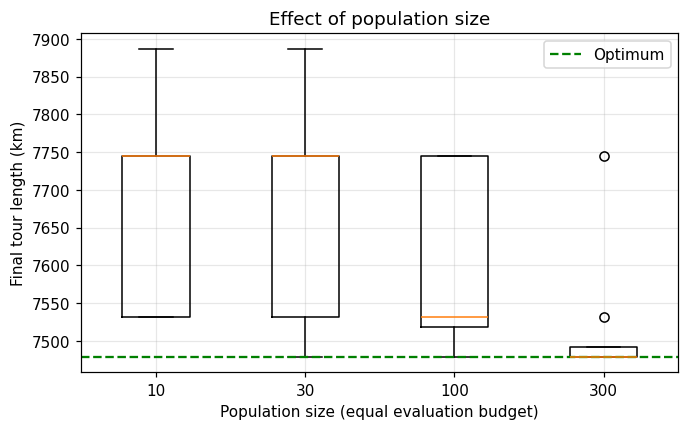

In [9]:
sizes = [10, 30, 100, 300]
gens_for = {s: 45000 // s for s in sizes}       # equal evaluation budget for each size
res2 = {s: [genetic_algorithm(pop_size=s, generations=gens_for[s], seed=k)[1] for k in range(8)] for s in sizes}
pop = pd.DataFrame({'Population': sizes, 'Generations': [gens_for[s] for s in sizes],
                    'Mean length (km)': [np.mean(res2[s]) for s in sizes],
                    'Best length (km)': [np.min(res2[s]) for s in sizes]}).round(1)
pop.to_csv('figures/population.csv', index=False)
print(pop.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([res2[s] for s in sizes], tick_labels=[str(s) for s in sizes])
ax.axhline(opt_len, color='green', ls='--', label='Optimum')
ax.set_xlabel('Population size (equal evaluation budget)'); ax.set_ylabel('Final tour length (km)')
ax.set_title('Effect of population size'); ax.legend()
fig.savefig('figures/population_size.png', bbox_inches='tight'); plt.show()

## 7. Worked Example of Order Crossover (viva demo)

With 8 cities, parents and cut points are fixed so the steps are traceable by hand.

In [10]:
P1 = [1, 2, 3, 4, 5, 6, 7, 8]
P2 = [3, 7, 5, 1, 6, 8, 2, 4]
a, b = 2, 4                                  # copy P1[2..4] = [3, 4, 5]
child = [None]*8
child[a:b+1] = P1[a:b+1]
fill = [g for g in P2 if g not in child[a:b+1]]
print('Parent 1 :', P1)
print('Parent 2 :', P2)
print('Slice kept from P1 (positions 2-4):', P1[a:b+1])
print('Remaining genes in P2 order      :', fill)
pos = 0
for i in range(8):
    if child[i] is None:
        child[i] = fill[pos]; pos += 1
print('Child    :', child)
assert sorted(child) == P1

tour = [1, 2, 3, 4, 5, 6, 7, 8]
print('\nInversion of positions 2..5 on', tour, '->', tour[:2] + tour[2:6][::-1] + tour[6:])

Parent 1 : [1, 2, 3, 4, 5, 6, 7, 8]
Parent 2 : [3, 7, 5, 1, 6, 8, 2, 4]
Slice kept from P1 (positions 2-4): [3, 4, 5]
Remaining genes in P2 order      : [7, 1, 6, 8, 2]
Child    : [7, 1, 3, 4, 5, 6, 8, 2]

Inversion of positions 2..5 on [1, 2, 3, 4, 5, 6, 7, 8] -> [1, 2, 6, 5, 4, 3, 7, 8]


## 8. Complexity and Limitations

Let $P$ be the population size, $G$ the generations and $n$ the number of cities.

- **Time:** each generation evaluates $P$ tours at $O(n)$ each, and crossover/mutation are $O(n)$ per child, so total $O(G \cdot P \cdot n)$.
- **Space:** $O(P \cdot n)$ for the population.
- **Exact alternative:** Held-Karp is $O(n^2 2^n)$ time and $O(n\,2^n)$ space, which is why it does not scale beyond roughly 25 cities.

**Limitations:** the GA gives no optimality guarantee, results depend on parameters and random seed, and premature convergence can occur when diversity is lost.

## 9. Conclusion

The GA finds tours within a small margin of the exact optimum on a problem with about $4.4\times10^{10}$ possible tours,
while evaluating only $45{,}000$ of them. It clearly beats random search and nearest-neighbour. The experiments show that:
mutation prevents stagnation (rate 0 performs worst, and higher rates did better here), and with a fixed evaluation budget the larger
populations (100 and 300) beat very small ones, which stagnate despite running more generations.
A single run can still get stuck in a local optimum (the seed-42 run above is about 3.6% above optimal), which is why results are reported over repeated runs.